# From simulation to a SN Ia Hubble diagram

This is the flagship cosmology use case of skysurvey: simulate Type Ia supernovae (SNe Ia) as nature makes them,
observe them with a ZTF-like survey, fit their lightcurves with the SALT2 model, standardize them and build a Hubble diagram.
Along the way you will see how well the fit recovers the true parameters and how the survey depth biases the
distances of the faintest objects (the Malmquist bias).

:::{note}
The lightcurve fits use {func}`sncosmo.fit_lc`, which requires the `iminuit` package (`pip install iminuit`).
Fitting several hundred lightcurves takes about a minute on a laptop.
:::

In [1]:
import inspect
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sncosmo
from astropy.cosmology import Planck18
from shapely import geometry

import skysurvey
from skysurvey.lcfit import fit_salt

## Simulate SNe Ia

{meth}`skysurvey.SNeIa.from_draw` draws the SN Ia parameters given by nature: redshift `z`, time of maximum `t0`,
SALT2 stretch `x1` (lightcurve width) and color `c`, sky position, and the peak absolute magnitude `magabs`
in the rest-frame B band (which follows the Tripp relation, see below). We draw 1500 SNe Ia up to $z=0.25$,
exploding over 180 days in a $50\times30$ deg patch of sky.

:::{tip}
`from_draw` does not take a random seed (yet), so the exact numbers in this page change slightly from one run to the next.
:::

In [2]:
radec = {"ra_range": [200, 250], "dec_range": [-20, 10]}
snia = skysurvey.SNeIa.from_draw(1500, zmax=0.25,
                                 tstart=58_000, tstop=58_180,
                                 radec=radec)
snia.data.head()

,z,x1,c,t0,ra,dec,magabs,magobs,template
0,0.12765,1.415,0.143,58158.835938,232.893753,-7.411237,-18.956566,19.999756,salt2
1,0.14035,0.560,-0.031,58133.519531,217.982361,-0.522434,-19.565399,19.614288,salt2
2,0.23075,0.450,0.161,58061.925781,228.516968,-8.982957,-18.838631,21.536127,salt2
3,0.24905,0.800,-0.079,58113.507812,239.993118,-6.451838,-19.806929,20.755241,salt2
4,0.15075,-0.865,0.059,58095.621094,240.075119,-18.005299,-19.051411,20.297525,salt2


## A ZTF-like survey

We now build a mock observing log mimicking the Zwicky Transient Facility (ZTF): 25 000 random pointings of a
camera with a 2-degree radius footprint over the same sky patch, in the `ztfg`, `ztfr` and (less often) `ztfi` bands.
With a zero point of 30 and a sky noise of about 1200 flux units, the $5\sigma$ limiting magnitude is
$30 - 2.5\log_{10}(5\times1200) \approx 20.5$, close to ZTF's typical depth. Each sky position is observed
every ~2 days on average.

In [3]:
rng = np.random.default_rng(42)
npointings = 25_000
logs = pd.DataFrame({"mjd": rng.uniform(57_970, 58_220, size=npointings),
                     "band": rng.choice(["ztfg", "ztfr", "ztfi"], size=npointings, p=[0.45, 0.45, 0.1]),
                     "skynoise": rng.normal(1200, 150, size=npointings),
                     "zp": 30., "gain": 1.})
logs["ra"], logs["dec"] = skysurvey.tools.utils.random_radec(npointings, rng=rng, **radec)

footprint = geometry.Point(0, 0).buffer(2)  # 2-degree radius circle
survey = skysurvey.Survey.from_pointings(logs, footprint=footprint)

## Build the dataset

{meth}`skysurvey.DataSet.from_targets_and_survey` matches each SN with the pointings that covered it and simulates
the observed fluxes and their errors (the noise draw is seeded).

In [4]:
dset = skysurvey.DataSet.from_targets_and_survey(snia, survey, seed=42)
# fluxes are computed in the AB system; the lightcurve fitter needs it as an explicit column.
dset.data["zpsys"] = "ab"
dset.data.head()

mjd  band     skynoise  gain    zp  fieldid  \
index index_obs                                                         
0     1964544    58104.820312  ztfr   925.236755   1.0  30.0   270682   
      1965643    58104.898438  ztfg  1371.526733   1.0  30.0   270682   
      1965962    58104.921875  ztfr  1102.152832   1.0  30.0   270682   
      1971326    58105.285156  ztfg  1370.660889   1.0  30.0   270682   
      1973616    58105.460938  ztfr  1176.475220   1.0  30.0   270682   

                        flux      fluxerr zpsys  
index index_obs                                  
0     1964544     281.935444   925.236760    ab  
      1965643   -1426.366021  1371.526750    ab  
      1965962     827.111914  1102.152836    ab  
      1971326    1289.195263  1370.660881    ab  
      1973616   -2295.344600  1176.475244    ab

## Quality cut

A lightcurve can only be fitted if it is well sampled around maximum light. We keep SNe with at least 7 detections
(points with flux/fluxerr $\geq 5$) between $-10$ and $+40$ rest-frame days around maximum, using
{meth}`skysurvey.DataSet.get_ndetection`. The fraction of SNe passing this cut drops at high redshift, where SNe are
faint compared to the survey depth.

602 of 1500 SNe Ia pass the cut


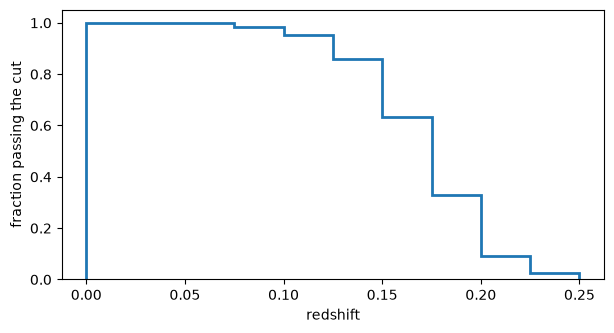

In [5]:
ndet = dset.get_ndetection(phase_range=[-10, 40])
good = ndet[ndet >= 7].index
print(f"{len(good)} of {len(snia.data)} SNe Ia pass the cut")

zbins = np.linspace(0, 0.25, 11)
z_all, z_good = snia.data["z"], snia.data.loc[good, "z"]
frac = np.histogram(z_good, zbins)[0] / np.histogram(z_all, zbins)[0]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.stairs(frac, zbins, lw=2)
ax.set(xlabel="redshift", ylabel="fraction passing the cut", ylim=(0, 1.05));

Here is a typical lightcurve that passed the cut; the lines show the true (input) model.

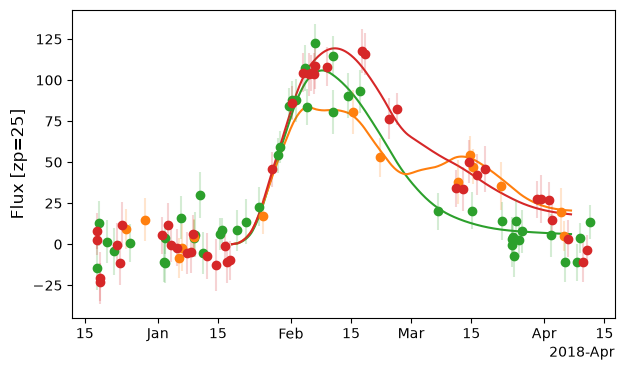

In [6]:
fig = dset.show_target_lightcurve(index=good[0])

## Fit the lightcurves with SALT2

{func}`skysurvey.lcfit.fit_salt` fits each lightcurve with the SALT2 model (via {func}`sncosmo.fit_lc`), with the
redshift fixed and `t0`, `x0` (amplitude), `x1` and `c` free. The fit starts from the true parameters: we set
`in_scatter={}` so that this starting point is not randomly perturbed (keeping the fit deterministic) and widen the default
`bounds` (half-widths around the starting values) so that they do not truncate the fitted values.

:::{tip}
For large samples, pass a `dask.distributed.Client` as `client=` to run the fits in parallel.
:::

In [7]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # harmless sncosmo/iminuit convergence chatter
    fits = fit_salt(dset, indexes=good, in_scatter={},
                    bounds={"t0": 10, "x1": 4, "c": 0.6})

fits = fits.astype(float)
truth = snia.data.loc[fits.index]
fits[["z", "t0", "t0_err", "x0", "x0_err", "x1", "x1_err", "c", "c_err"]].head()

,z,t0,t0_err,x0,x0_err,x1,x1_err,c,c_err
0,0.12765,58158.809802,0.635329,0.000160,0.000009,1.670609,0.743989,0.108845,0.050712
1,0.14035,58133.734848,0.424874,0.000220,0.000010,0.869666,0.430317,-0.015233,0.042767
4,0.15075,58095.096098,0.789283,0.000104,0.000011,-0.982154,0.810248,0.212656,0.102037
7,0.14945,58009.006440,0.473161,0.000177,0.000008,-1.794218,0.489811,-0.095191,0.052030
9,0.14565,58134.992971,0.613528,0.000202,0.000010,1.745850,0.562946,0.018506,0.049504


## Fitted vs true parameters

Since we know the truth, we can check the fit through the *pulls*, (fitted - true) / error. For an unbiased fit with
correct errors, the pulls follow a standard normal distribution $\mathcal{N}(0, 1)$. A standard deviation
slightly below 1 means the errors are a bit conservative: SALT2 adds a model uncertainty (`modelcov=True`)
that is larger than the actual mismatch, since here the data were simulated with the very same model.

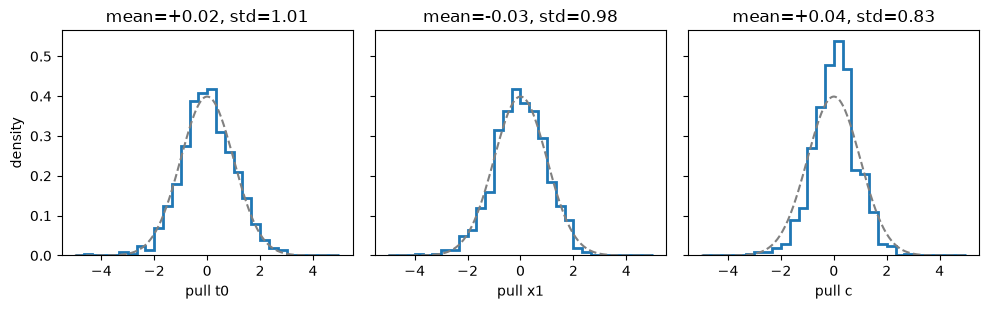

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
xx = np.linspace(-5, 5, 200)
for ax, key in zip(axes, ["t0", "x1", "c"]):
    pull = (fits[key] - truth[key]) / fits[f"{key}_err"]
    ax.hist(pull, bins=np.linspace(-5, 5, 31), density=True, histtype="step", lw=2)
    ax.plot(xx, np.exp(-xx**2 / 2) / np.sqrt(2 * np.pi), color="0.5", ls="--")
    ax.set(xlabel=f"pull {key}", title=f"mean={pull.mean():+.2f}, std={pull.std():.2f}")
axes[0].set_ylabel("density")
fig.tight_layout()

## Standardize with the Tripp relation

SNe Ia are *standardizable* candles: once corrected for stretch and color, their peak absolute magnitude is nearly
constant. The `SNeIa` model draws `magabs` from the Tripp (1998) relation
{meth}`~skysurvey.SNeIaMagnitude.tripp1998`, $M_B = M_0 + \alpha\,x_1 + \beta\,c$ plus a grey intrinsic
scatter. Let us read the true values of $M_0$, $\alpha$ and $\beta$ used in the simulation (note that in
skysurvey's convention, $\alpha$ is negative).

In [9]:
tripp_defaults = inspect.signature(skysurvey.target.snia.SNeIaMagnitude.tripp1998).parameters
alpha, beta = tripp_defaults["alpha"].default, tripp_defaults["beta"].default
M0, sigmaint = (snia.model.model["magabs"]["kwargs"][k] for k in ["mabs", "sigmaint"])
print(f"{M0=}, {alpha=}, {beta=}, {sigmaint=}")

M0=-19.3, alpha=-0.14, beta=3.15, sigmaint=0.1


The observed peak magnitude $m_B$ is the rest-frame B-band peak magnitude of the fitted SALT2 model. The distance modulus
is then $\mu = m_B - M_0 - \alpha\,x_1 - \beta\,c$. We propagate the fit errors and covariances on $(x_0, x_1, c)$ into
$\mu$, and add the intrinsic scatter in quadrature.

In [10]:
model = sncosmo.Model("salt2")
mb = []
for _, row in fits.iterrows():
    model.set(**row[["z", "t0", "x0", "x1", "c"]])
    mb.append(model.source_peakmag("bessellb", "ab"))
fits["mb"] = mb

k = 2.5 / np.log(10)  # dmb/dx0 = -k / x0
dmb = -k / fits["x0"]
fits["mu"] = fits["mb"] - M0 - alpha * fits["x1"] - beta * fits["c"]
var_mu = (dmb**2 * fits["cov_x0x0"] + alpha**2 * fits["cov_x1x1"] + beta**2 * fits["cov_cc"]
          - 2 * alpha * dmb * fits["cov_x0x1"] - 2 * beta * dmb * fits["cov_x0c"]
          + 2 * alpha * beta * fits["cov_x1c"])
fits["mu_err"] = np.sqrt(var_mu + sigmaint**2)

## The Hubble diagram

We compare the distance moduli to the Planck18 cosmology (also the cosmology used in the simulation), and look at the
Hubble residuals $\mu - \mu_\mathrm{Planck18}(z)$ as a function of redshift.

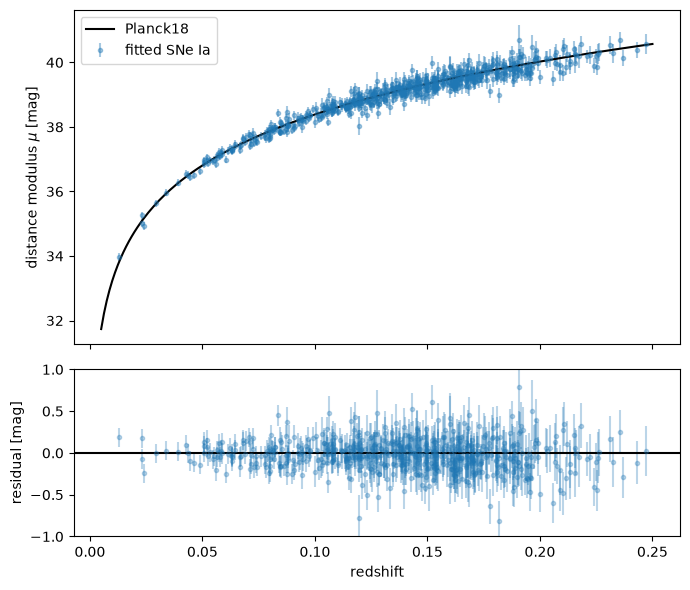

In [11]:
fits["hr"] = fits["mu"] - Planck18.distmod(fits["z"].to_numpy()).value
zz = np.linspace(0.005, 0.25, 200)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, height_ratios=[2, 1])
ax.errorbar(fits["z"], fits["mu"], yerr=fits["mu_err"], fmt="o", ms=3, alpha=0.4, label="fitted SNe Ia")
ax.plot(zz, Planck18.distmod(zz).value, color="k", label="Planck18")
ax.set(ylabel=r"distance modulus $\mu$ [mag]")
ax.legend()

axr.errorbar(fits["z"], fits["hr"], yerr=fits["mu_err"], fmt="o", ms=3, alpha=0.3)
axr.axhline(0, color="k")
axr.set(xlabel="redshift", ylabel="residual [mag]", ylim=(-1, 1))
fig.tight_layout()

## Malmquist bias

At high redshift, only the SNe that happen to be brighter than average (positive intrinsic scatter fluctuation, bluer
color, ...) pass the detection cut: the selected sample is biased towards bright objects, hence towards *negative*
Hubble residuals. This is the Malmquist bias. To show that it is a selection effect and not a fitting artifact, we also
compute the residuals from the *true* parameters of the same SNe (this is just the intrinsic scatter), and compare
them to those of all simulated SNe.

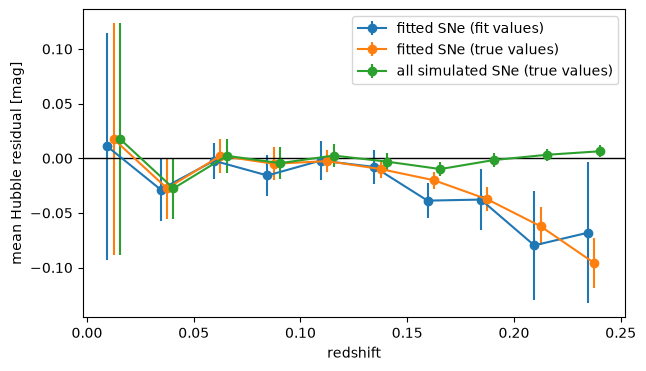

In [12]:
def true_residual(data):
    mu_true = data["magobs"] - M0 - alpha * data["x1"] - beta * data["c"]
    return mu_true - Planck18.distmod(data["z"].to_numpy()).value

def binned_mean(z, values):
    groups = pd.Series(np.asarray(values)).groupby(pd.cut(np.asarray(z), zbins), observed=False)
    return groups.mean(), groups.sem()

zcenters = 0.5 * (zbins[1:] + zbins[:-1])
samples = {"fitted SNe (fit values)": (fits["z"], fits["hr"]),
           "fitted SNe (true values)": (truth["z"], true_residual(truth)),
           "all simulated SNe (true values)": (snia.data["z"], true_residual(snia.data))}

fig, ax = plt.subplots(figsize=(7, 4))
for i, (label, (z, values)) in enumerate(samples.items()):
    mean, sem = binned_mean(z, values)
    ax.errorbar(zcenters + (i - 1) * 0.003, mean, yerr=sem, fmt="o-", label=label)
ax.axhline(0, color="k", lw=1)
ax.set(xlabel="redshift", ylabel="mean Hubble residual [mag]")
ax.legend();

All simulated SNe scatter around zero at all redshifts, while the selected ones drift towards negative residuals above
$z\sim0.15$, both with fitted and true parameters: the bias comes from the selection. A cosmological analysis must
model (and correct for) this bias, which is exactly what simulations like this one are used for.

## Next steps

- [Detection efficiency](detection_efficiency.ipynb): quantify how the selection depends on redshift and survey depth.
- [SNe Ia](../transientclasses/sne_ia.ipynb): learn more about the `SNeIa` model and how to change its parameters
  (e.g. the Tripp coefficients or the color and stretch distributions).
- [Survey strategy](survey_strategy.ipynb): compare cadences and depths for your own survey.